# 10 · Stage 4: bench $R_i$ sweeps, cycle maps and the tipping diagram

**Purpose.** Analyses the bench recordings of configuration B, in which the input resistor $R_i$ is swept along one fixed staircase at different speeds. For every run it finds the peak amplitude of every sweep cycle, decides the long-time state (re-ignites every cycle, stays off, or mixed) and locates the first switch-off. It answers: along the same gain path, does the speed alone decide whether the oscillation survives?

**In the report.** Chapter 7, Secs. 7.1–7.3: Table 7.1, Figs. 7.1–7.4 (bench part), Eq. (7.1). The run table feeds notebook 11.

## Theory

Configuration B: $R_F = 90\,\mathrm{k\Omega}$, $R_i = 41\,\mathrm{k\Omega}$ + potentiometer (31 steps of 322.6 Ω), so $G = 1 + R_F/R_i$ runs from 3.20 down to 2.76. The sketch (`Ri_sweep_staircase.ino`, notebook 03) first holds the highest gain for 32 steps, so every run starts oscillating, then sweeps $R_i$ up and down with period $64\tau$.

With the measured bench threshold $G_c \approx 3.08$ only seven of the 32 positions lie above threshold. Each pass above threshold allows growth by $e^{\Gamma_+}$ with $\Gamma_+ \propto 1/\lambda$ (Eq. 2.37). If that is enough to climb from the noise floor to full size, the oscillation re-ignites every cycle; if not, it switches off once and stays off: rate-induced tipping (Sec. 2.6, notebook 11).

## Method

1. **Load** each run: two columns, no header (time from the trigger's rising edge in s, output in V). Time stamps are slightly uneven, so the record is resampled onto a uniform grid at the median interval. The step time comes from the file name `..._<delay>a.csv` (ms).
2. **Envelope**: running maximum of the positive half-wave over `ENV_WINDOW` = 30 ms (about two periods), backward and forward windows combined. The full-size level $A_{\rm sat}$ is the run's own initial oscillation (median envelope during the initial hold).
3. **Cycles**: cycle $n$ is the window of $\pm 32\tau$ around the middle of the $n$-th bottom hold (highest gain). Its peak $A_{\rm peak}/A_{\rm sat}$ is recorded; it "re-ignites" if the peak reaches 90 %.
4. **Step time**: if the run keeps switching on, the true sweep period is fitted to the 50 % onset times of the cycles (accepted if within 5 % of nominal); otherwise the nominal delay is used. True rate $\lambda = \Delta R/\tau$.
5. **State**: "switches back on every cycle" if at least 80 % of cycles re-ignite, "stays off" if none does, otherwise "mixed".
6. **First switch-off**: the last downward crossing of 10 % of $A_{\rm sat}$ during the first rising-$R_i$ pass, converted to $R_i$ with the mid-step line. Runs whose switch-off time, counted in steps after the start of the sweep, is an outlier (more than 5 robust standard deviations or 2 steps from the median) are flagged `time_origin_ok = False`: for those the trigger reference is unreliable.
7. **Critical rate**: the bracket between the fastest run that re-ignites and the slowest that stays off.

## Requirements

Python 3.9+, `numpy`, `pandas`, `scipy`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
DATA_FOLDER  = "../data/stage4/bench"            # recordings to analyse (sample: 55 ms and 50 ms runs)
FILE_PATTERN = "time_series_cropped_*a.csv"      # <delay> in ..._<delay>a.csv = Arduino step delay (ms)
FULL_RESULTS = "../data/stage4/results"          # run and cycle tables of all 19 report runs (made by this notebook), or None
OUT_DIR      = "outputs/10_stage4_bench"

# circuit / protocol (configuration B)
R_F = 90e3; RI_0 = 41e3; DELTA_RI = 10e3; N_STEPS = 31; STEPS_PER_HALF = 32
PRE_HOLD_STEPS = 32        # the sketch starts with 32 decrements at tap 0 -> a hold of 32 steps
TRIG_WIDTH = 0.050         # s; t = 0 in the files is the trigger's rising edge, the sweep starts at its falling edge
R_WIEN, C_WIEN = 2.17e3, 1e-6
# analysis (report values)
ENV_WINDOW = 0.03          # s, envelope window (about two oscillation periods)
FULL_ON = 0.90             # a cycle re-ignites if its peak reaches 90 % of full size
LOW, HIGH = 0.10, 0.90
TRACK_FRACTION = 0.8       # at least this fraction of cycles re-igniting -> "switches back on every cycle"

## 1. Loading, envelope and the configuration-B staircase

In [2]:
import os, re, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d
os.makedirs(OUT_DIR, exist_ok=True)
OMEGA0 = 1 / (R_WIEN * C_WIEN)
STEP_RI = DELTA_RI / N_STEPS
TOP_TAP = min(STEPS_PER_HALF, N_STEPS)

def delay_of(path):
    m = re.search(r"_(\d+(?:\.\d+)?)a\.csv$", os.path.basename(path))
    return float(m.group(1)) if m else np.nan


def load_run(path):
    """Two columns, no header: time (s), Vout (V). Resampled onto a uniform time grid."""
    d = pd.read_csv(path, header=None).apply(pd.to_numeric, errors="coerce").dropna()
    t, v = d.iloc[:, 0].to_numpy(float), d.iloc[:, 1].to_numpy(float)
    t, idx = np.unique(t, return_index=True)
    v = v[idx]
    dt = float(np.median(np.diff(t)))
    grid = np.arange(t[0], t[-1], dt)
    return grid, np.interp(grid, t, v), dt


def runmax(x, n, side):
    """Running max: side='back' -> window [i-n+1, i] (exact on rising edges), 'fwd' -> [i, i+n-1] (falling edges)."""
    o = (n - 1) // 2 if side == "back" else -(n // 2)
    return maximum_filter1d(x, n, origin=o, mode="nearest")


def envelope(v, dt, window=None):
    n = max(3, int(round((window or ENV_WINDOW) / dt)))
    pos = np.clip(v, 0, None)
    return np.minimum(runmax(pos, n, "back"), runmax(pos, n, "fwd"))


def first_cross_up(t, y, level, lo, hi):
    """First upward crossing of `level` in [lo, hi), interpolated; NaN if y starts above level or never crosses."""
    if hi - lo < 2 or y[lo] >= level:
        return np.nan
    idx = np.where(y[lo:hi] >= level)[0]
    if len(idx) == 0:
        return np.nan
    i = lo + idx[0]
    return t[i - 1] + (level - y[i - 1]) * (t[i] - t[i - 1]) / (y[i] - y[i - 1])


def last_cross_down(t, y, level, lo, hi):
    """Last downward crossing of `level` in [lo, hi); NaN if y does not end below level."""
    if hi - lo < 2 or y[hi - 1] >= level:
        return np.nan
    idx = np.where(y[lo:hi] >= level)[0]
    if len(idx) == 0:
        return np.nan
    j = lo + idx[-1]
    return t[j] + (y[j] - level) * (t[j + 1] - t[j]) / (y[j] - y[j + 1])


# ---------------- pot model: exactly the Arduino loop ----------------
def sweep_x(t, tau):
    """Steps since the first increment (negative during the initial hold) and position u in the 64-step cycle."""
    t1 = TRIG_WIDTH + PRE_HOLD_STEPS * tau
    x = (np.asarray(t, float) - t1) / tau
    return x, np.mod(x, 2 * STEPS_PER_HALF)


def k_lin(t, tau):
    """Tap number as a straight line through the middle of each step (flat on the holds); 0 before the sweep."""
    x, u = sweep_x(t, tau)
    k = np.clip(np.minimum(u + 0.5, TOP_TAP + STEPS_PER_HALF - 0.5 - u), 0, TOP_TAP)
    return np.where(x < 0, 0.0, k)


def Ri_of_t(t, tau):
    return RI_0 + STEP_RI * k_lin(t, tau)


def G_of_Ri(Ri):
    return 1 + R_F / np.asarray(Ri, float)


def branch_of(t, tau):
    """Part of the sweep at time t (as text)."""
    x, u = sweep_x(np.atleast_1d(t), tau)
    out = np.empty(x.shape, dtype=object)
    for i, (xi, ui) in enumerate(zip(x, u)):
        if xi < 0:
            out[i] = "initial hold (G highest)"
        elif ui < TOP_TAP - 0.5:
            out[i] = "Ri rising (G falling)"
        elif ui < STEPS_PER_HALF - 0.5:
            out[i] = "top hold (G lowest)"
        elif ui < TOP_TAP + STEPS_PER_HALF - 0.5:
            out[i] = "Ri falling (G rising)"
        else:
            out[i] = "bottom hold (G highest)"
    return out

## 2. Per-run analysis and classification

In [3]:
def analyse_run(path, tau_override=None):
    D = delay_of(path)
    t, v, dt = load_run(path)
    tau_nom = D / 1000.0

    # baseline (median of the quiet parts), envelope, rail = level of the run's own initial oscillation
    raw_env = envelope(np.abs(v), dt)
    quiet = raw_env < 0.1 * np.percentile(raw_env, 99)
    if quiet.sum() > 100:
        v = v - np.median(v[quiet])
    env = envelope(v, dt)
    t1_nom = TRIG_WIDTH + PRE_HOLD_STEPS * tau_nom
    init = (t > 0.1) & (t < max(t1_nom - 0.05, 0.2))
    V_rail = float(np.median(env[init])) if init.sum() > 10 else float(np.percentile(env, 99.5))

    def per_cycle(tau):
        t1 = TRIG_WIDTH + PRE_HOLD_STEPS * tau
        rows, n = [], 1
        while True:
            c = t1 + (2 * STEPS_PER_HALF * n - 1) * tau          # middle of the n-th bottom hold (G highest)
            a, b = c - STEPS_PER_HALF * tau, c + STEPS_PER_HALF * tau
            if b > t[-1]:
                break
            lo, hi = np.searchsorted(t, a), np.searchsorted(t, b)
            pk = env[lo:hi].max()
            r = dict(cycle=n, A_peak=pk / V_rail, V_peak=pk, t_start=t[lo], t_end=t[hi - 1],
                     full_on=bool(pk >= FULL_ON * V_rail))
            r["t_on50"] = first_cross_up(t, env, 0.5 * V_rail, lo, hi)
            r["t_on90"] = first_cross_up(t, env, HIGH * V_rail, lo, hi)
            r["t_off50"] = last_cross_down(t, env, 0.5 * V_rail, lo, hi) if np.isfinite(r["t_on50"]) else np.nan
            r["t_off10"] = last_cross_down(t, env, LOW * V_rail, lo, hi) if np.isfinite(r["t_on90"]) else np.nan
            rows.append(r)
            n += 1
        cols = ["cycle", "A_peak", "V_peak", "t_start", "t_end", "full_on", "t_on50", "t_on90", "t_off50", "t_off10"]
        return t1, pd.DataFrame(rows, columns=cols)

    # pass 1 with the nominal delay; if the run keeps switching on, measure tau from the burst onsets
    t1, cyc = per_cycle(tau_nom)
    tau, tau_src = tau_nom, "nominal (file name)"
    if tau_override is not None:
        tau, tau_src = tau_override, "given"
    else:
        ok = cyc.t_on50.notna()
        if ok.sum() >= 3:
            T_meas = np.polyfit(cyc.cycle[ok].astype(float), cyc.t_on50[ok].astype(float), 1)[0]
            if abs(T_meas / (2 * STEPS_PER_HALF * tau_nom) - 1) < 0.05:
                tau, tau_src = T_meas / (2 * STEPS_PER_HALF), "measured (burst onsets)"
    t1, cyc = per_cycle(tau)

    # first switch-off of the initial oscillation
    first_hi = np.searchsorted(t, t1 + (STEPS_PER_HALF - 1) * tau)
    t_off10_1 = last_cross_down(t, env, LOW * V_rail, 0, first_hi)
    t_off50_1 = last_cross_down(t, env, 0.5 * V_rail, 0, first_hi)

    for col in ["t_on50", "t_on90", "t_off50", "t_off10"]:
        key = col[2:]
        x = cyc[col].to_numpy(float)
        cyc["Ri_" + key] = np.where(np.isfinite(x), Ri_of_t(np.nan_to_num(x), tau), np.nan)
        cyc["G_" + key] = G_of_Ri(cyc["Ri_" + key])
        cyc["branch_" + key] = [branch_of(xx, tau)[0] if np.isfinite(xx) else "" for xx in x]

    lam = STEP_RI / tau
    Ri1 = float(Ri_of_t(t_off10_1, tau)) if np.isfinite(t_off10_1) else np.nan
    info = dict(file=os.path.basename(path), delay_ms=D, tau_ms=tau * 1e3, tau_source=tau_src,
                lambda_ohm_s=lam, dt_ms=dt * 1e3, duration_s=t[-1] - t[0], V_rail=V_rail, n_cycles=len(cyc),
                t_first_off10=t_off10_1, t_first_off50=t_off50_1,
                Ri_first_off10=Ri1, G_first_off10=float(G_of_Ri(Ri1)) if np.isfinite(Ri1) else np.nan)
    return info, cyc, (t, v, env)


def classify(cyc):
    """Long-time state from all complete cycles after the first switch-off."""
    if len(cyc) == 0:
        return "no complete cycle", np.nan
    f = float(cyc.full_on.mean())
    if f >= TRACK_FRACTION:
        return "switches back on every cycle", f
    if f == 0:
        return "stays off (never switches back on)", f
    return "mixed", f


def analyse_folder(folder, pattern, tau_overrides=None):
    files = sorted(glob.glob(os.path.join(folder, pattern)), key=delay_of)
    if not files:
        raise FileNotFoundError(f"No files matching {pattern!r} in {os.path.abspath(folder)!r}")
    infos, cycs, traces = [], {}, {}
    for f in files:
        D = delay_of(f)
        info, cyc, tr = analyse_run(f, tau_override=(tau_overrides or {}).get(D))
        state, frac = classify(cyc)
        info.update(state=state, frac_full_on=frac,
                    A_peak_median=float(cyc.A_peak.median()) if len(cyc) else np.nan,
                    A_peak_min=float(cyc.A_peak.min()) if len(cyc) else np.nan,
                    A_peak_max=float(cyc.A_peak.max()) if len(cyc) else np.nan)
        infos.append(info); cycs[D] = cyc; traces[D] = tr
    runs = pd.DataFrame(infos).sort_values("lambda_ohm_s").reset_index(drop=True)
    return runs, cycs, traces

## 3. Analyse the recordings in `DATA_FOLDER`

In [4]:
runs, cycs, traces = analyse_folder(DATA_FOLDER, FILE_PATTERN)
runs["steps_to_first_off"] = (runs.t_first_off10 - (TRIG_WIDTH + PRE_HOLD_STEPS * runs.tau_ms / 1e3)) / (runs.tau_ms / 1e3)
med = runs.steps_to_first_off.median(); mad = 1.4826 * (runs.steps_to_first_off - med).abs().median()
runs["time_origin_ok"] = (runs.steps_to_first_off - med).abs() <= max(5 * mad, 2.0)
cyc_table = pd.concat([c.assign(delay_ms=d) for d, c in cycs.items()], ignore_index=True)
runs.to_csv(os.path.join(OUT_DIR, "runs.csv"), index=False); cyc_table.to_csv(os.path.join(OUT_DIR, "cycles.csv"), index=False)
cols = ["delay_ms", "tau_ms", "lambda_ohm_s", "n_cycles", "state", "frac_full_on", "A_peak_min", "A_peak_max", "Ri_first_off10", "time_origin_ok"]
print(runs[cols].round(3).to_string(index=False))

 delay_ms  tau_ms  lambda_ohm_s  n_cycles                              state  frac_full_on  A_peak_min  A_peak_max  Ri_first_off10  time_origin_ok
     55.0  55.222      5841.491        16       switches back on every cycle           1.0       0.985       1.007       44351.803            True
     50.0  50.000      6451.613        17 stays off (never switches back on)           0.0       0.022       0.176       44458.726            True


## 4. Envelopes of the analysed runs (as Figs. 7.1 and 7.2)

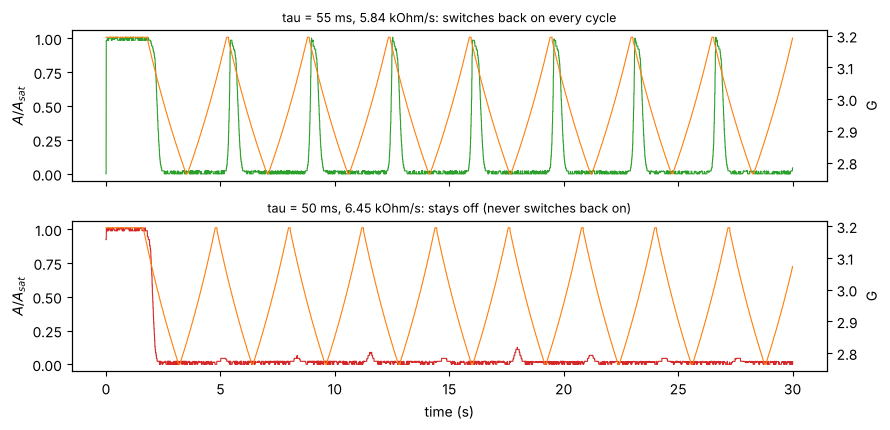

In [5]:
COL = {"switches back on every cycle": "tab:green", "stays off (never switches back on)": "tab:red", "mixed": "tab:orange", "no complete cycle": "gray"}
fig, axs = plt.subplots(len(runs), 1, figsize=(9, 2.2 * len(runs)), sharex=True, squeeze=False)
for ax, (_, r) in zip(axs[:, 0], runs.iterrows()):
    t, v, env = traces[r.delay_ms]; s = t <= 30
    ax.plot(t[s], env[s] / r.V_rail, color=COL[r.state], lw=0.8)
    a2 = ax.twinx(); ts = np.linspace(0, 30, 6000); a2.plot(ts, G_of_Ri(Ri_of_t(ts, r.tau_ms / 1e3)), color="tab:orange", lw=0.8)
    a2.set_ylabel("G"); ax.set_ylabel(r"$A/A_{sat}$")
    ax.set_title(f"tau = {r.delay_ms:.0f} ms, {r.lambda_ohm_s/1e3:.2f} kOhm/s: {r.state}", fontsize=9)
axs[-1, 0].set_xlabel("time (s)"); fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "envelopes.png"), dpi=130); plt.show()

## 5. Table 7.1, cycle map and tipping diagram

These use the run and cycle tables of all 19 report runs in `FULL_RESULTS` (written by sections 1–3 of this notebook on the full dataset). Set `FULL_RESULTS = None` to use only the runs analysed above.

 delay_ms  lambda_ohm_s  cycles  reignited  A_peak_min  A_peak_max                              state
    100.0       3214.97      21         21        1.02        1.02       switches back on every cycle
     75.0       4285.37      28         28        0.96        1.02       switches back on every cycle
     70.0       4591.03      12         12        1.00        1.02       switches back on every cycle
     67.0       4796.48      13         13        1.00        1.01       switches back on every cycle
     66.0       4869.29      13         13        1.00        1.02       switches back on every cycle
     58.0       5589.59      15         14        0.56        1.02       switches back on every cycle
     56.0       5738.35      15         15        0.96        0.99       switches back on every cycle
     55.0       5841.49      16         16        0.99        1.01       switches back on every cycle
     54.0       5949.98      16         16        0.99        1.01       switches 

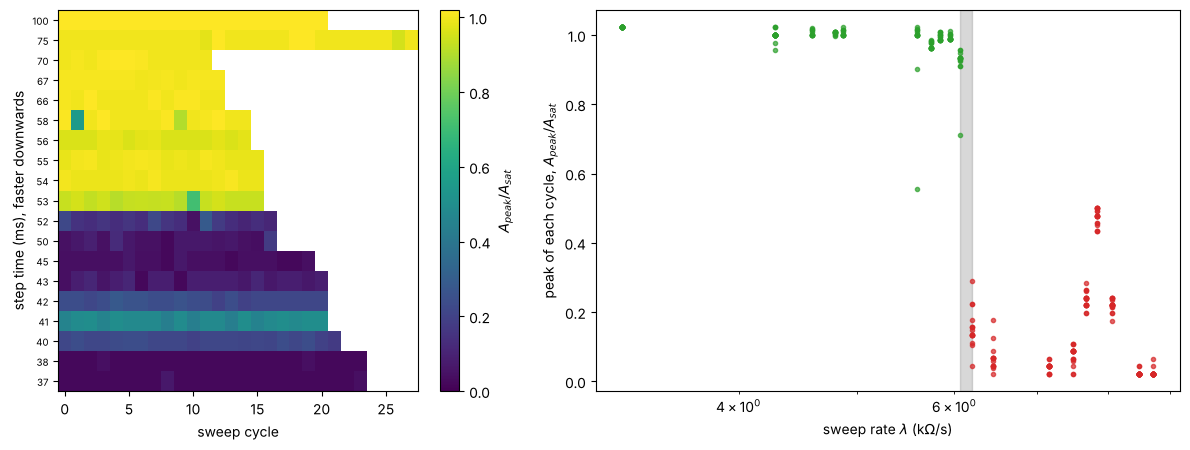

In [6]:
if FULL_RESULTS:
    R = pd.read_csv(os.path.join(FULL_RESULTS, "bench_runs.csv")); Cy = pd.read_csv(os.path.join(FULL_RESULTS, "bench_cycles.csv"))
else:
    R, Cy = runs, cyc_table
R = R.sort_values("lambda_ohm_s").reset_index(drop=True)
Cy["reignited"] = Cy.A_peak >= FULL_ON
t71 = R.assign(cycles=R.n_cycles, reignited=[int(Cy[Cy.delay_ms == d].reignited.sum()) for d in R.delay_ms])[
    ["delay_ms", "lambda_ohm_s", "cycles", "reignited", "A_peak_min", "A_peak_max", "state"]].sort_values("delay_ms", ascending=False)
print(t71.round(2).to_string(index=False)); t71.to_csv(os.path.join(OUT_DIR, "table_7_1.csv"), index=False)

ON, OFF = "switches back on every cycle", "stays off (never switches back on)"
lam_lo, lam_hi = R[R.state == ON].lambda_ohm_s.max(), R[R.state == OFF].lambda_ohm_s.min()
print(f"\ncritical rate: {lam_lo/1e3:.2f} < lambda_c < {lam_hi/1e3:.2f} kOhm/s  ({100*(lam_hi/lam_lo-1):.1f} % window)")

n_max = int(Cy.groupby("delay_ms").cycle.max().max())
M = np.full((len(R), n_max), np.nan)
for i, r in R.iterrows():
    a = Cy[Cy.delay_ms == r.delay_ms].sort_values("cycle").A_peak.to_numpy(); M[i, :len(a)] = a
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1, 1.3]))
im = axs[0].imshow(np.ma.masked_invalid(M), aspect="auto", cmap="viridis", vmin=0, vmax=1.02, interpolation="nearest")
axs[0].set_yticks(range(len(R))); axs[0].set_yticklabels([f"{d:.0f}" for d in R.delay_ms], fontsize=7)
axs[0].set_xlabel("sweep cycle"); axs[0].set_ylabel("step time (ms), faster downwards"); fig.colorbar(im, ax=axs[0], label=r"$A_{peak}/A_{sat}$")
for _, r in R.iterrows():
    a = Cy[Cy.delay_ms == r.delay_ms].A_peak.to_numpy()
    axs[1].plot(np.full(len(a), r.lambda_ohm_s / 1e3), a, "o", ms=3, color=COL[r.state], alpha=0.7)
axs[1].axvspan(lam_lo / 1e3, lam_hi / 1e3, color="gray", alpha=0.3)
axs[1].set_xscale("log"); axs[1].set_xlabel(r"sweep rate $\lambda$ (k$\Omega$/s)"); axs[1].set_ylabel(r"peak of each cycle, $A_{peak}/A_{sat}$")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "cyclemap_and_tipping.png"), dpi=150); plt.show()

## Check against the report

In [7]:
if FULL_RESULTS:
    off_runs = R[R.state == OFF]
    checks = {
        "19 runs: 10 re-ignite every cycle, 9 stay off": len(R) == 19 and (R.state == ON).sum() == 10 and len(off_runs) == 9,
        "Eq. 7.1: 6.06 < lambda_c < 6.20 kOhm/s": round(lam_lo / 1e3, 2) == 6.06 and round(lam_hi / 1e3, 2) == 6.20,
        "187 cycles in the runs that stay off, none above half of full size": int(off_runs.n_cycles.sum()) == 187 and off_runs.A_peak_max.max() <= 0.505,
        "Table 7.1 rows: tau = 100 ms -> 3.21 kOhm/s, 21 cycles; tau = 37 ms -> 8.72 kOhm/s, 24 cycles":
            abs(R[R.delay_ms == 100].lambda_ohm_s.iloc[0] - 3210) < 10 and int(R[R.delay_ms == 100].n_cycles.iloc[0]) == 21
            and abs(R[R.delay_ms == 37].lambda_ohm_s.iloc[0] - 8720) < 10 and int(R[R.delay_ms == 37].n_cycles.iloc[0]) == 24,
    }
    for k, ok in checks.items(): print(("PASS " if ok else "FAIL ") + k)
for _, r in runs.iterrows():                       # the sample runs against the full table
    if FULL_RESULTS:
        f = R[R.delay_ms == r.delay_ms].iloc[0]
        ok = f.state == r.state and abs(f.lambda_ohm_s - r.lambda_ohm_s) < 0.5 and int(f.n_cycles) == int(r.n_cycles)
        print(("PASS" if ok else "FAIL") + f" sample run tau = {r.delay_ms:.0f} ms reproduces its row of the full table ({r.state}, {r.lambda_ohm_s:.0f} ohm/s)")

PASS 19 runs: 10 re-ignite every cycle, 9 stay off
PASS Eq. 7.1: 6.06 < lambda_c < 6.20 kOhm/s
PASS 187 cycles in the runs that stay off, none above half of full size
PASS Table 7.1 rows: tau = 100 ms -> 3.21 kOhm/s, 21 cycles; tau = 37 ms -> 8.72 kOhm/s, 24 cycles
PASS sample run tau = 55 ms reproduces its row of the full table (switches back on every cycle, 5841 ohm/s)
PASS sample run tau = 50 ms reproduces its row of the full table (stays off (never switches back on), 6452 ohm/s)


## Using your own recordings

Put two-column CSV files (time from the trigger's rising edge in s, output in V, no header) named `<anything>_<delay>a.csv` in `DATA_FOLDER`, where `<delay>` is the Arduino step delay in ms. If your sketch has no initial hold, set `PRE_HOLD_STEPS = 0`. Change the circuit values for another configuration; the cycle windows, the staircase model and the classification follow from them.